# Assignment 4 — End-to-end ML Project

Dataset: [Life Expectancy (WHO) on Kaggle](https://www.kaggle.com/kumarajarshi/life-expectancy-who)

Complete each question in the code cell directly below it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from pandas.plotting import scatter_matrix

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import GridSearchCV



## 1. Read the data into Google Colab using the `.read_csv()` function.

In [2]:
path = kagglehub.dataset_download("kumarajarshi/life-expectancy-who")

print("Path to dataset files:", path)
os.listdir(path)

Using Colab cache for faster access to the 'life-expectancy-who' dataset.
Path to dataset files: /kaggle/input/life-expectancy-who


['Life Expectancy Data.csv']

In [3]:
file_name = "Life Expectancy Data.csv"
df = pd.read_csv(os.path.join(path, file_name))

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

## 2. For each country in the dataframe, keep only the most recent year of data (2015) and remove the remaining rows.

In [4]:
df2 = df.loc[df["Year"] == 2015]
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, 0 to 2922
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          183 non-null    object 
 1   Year                             183 non-null    int64  
 2   Status                           183 non-null    object 
 3   Life expectancy                  183 non-null    float64
 4   Adult Mortality                  183 non-null    float64
 5   infant deaths                    183 non-null    int64  
 6   Alcohol                          6 non-null      float64
 7   percentage expenditure           183 non-null    float64
 8   Hepatitis B                      174 non-null    float64
 9   Measles                          183 non-null    int64  
 10   BMI                             181 non-null    float64
 11  under-five deaths                183 non-null    int64  
 12  Polio                     

## 3. Keep only the listed features, the country name, and the target in the dataframe; remove all other features. Index the dataframe using the country name.

Features: `Status`, `Hepatitis B`, `Polio`, `Diphtheria`, `BMI`, `thinness 1-19 years`, `Alcohol`, `GDP`, `percentage expenditure`, `Income composition of resources`, and `Schooling`.

Target: `Life expectancy`.

In [5]:
features = ["Status", "Hepatitis B", "Polio", "Diphtheria", "BMI", "thinness 1-19 years", "Alcohol", "GDP", "percentage expenditure", "Income composition of resources", "Schooling"]

# Clean column names in df2 to remove leading/trailing spaces and normalize internal spaces
df2.columns = df2.columns.str.strip().str.replace('  ', ' ')

df3 = df2.loc[:, ["Country", "Life expectancy"] + features].set_index("Country")
df3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, Afghanistan to Zimbabwe
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Life expectancy                  183 non-null    float64
 1   Status                           183 non-null    object 
 2   Hepatitis B                      174 non-null    float64
 3   Polio                            183 non-null    float64
 4   Diphtheria                       183 non-null    float64
 5   BMI                              181 non-null    float64
 6   thinness 1-19 years              181 non-null    float64
 7   Alcohol                          6 non-null      float64
 8   GDP                              154 non-null    float64
 9   percentage expenditure           183 non-null    float64
 10  Income composition of resources  173 non-null    float64
 11  Schooling                        173 non-null    float64
dtypes: float64(1

## 4. Print the first and last ten rows of the dataframe using `.head()` and `.tail()`. How many observations (sample size) are there in total?

In [6]:
print("First 10 rows:")
print(df3.head(10))
print("\n")

print("Last 10 rows:")
print(df3.tail(10))

print("\n")
print(f'There are {df3.shape[0]} observations in total')

First 10 rows:
                     Life expectancy      Status  Hepatitis B  Polio  \
Country                                                                
Afghanistan                     65.0  Developing         65.0    6.0   
Albania                         77.8  Developing         99.0   99.0   
Algeria                         75.6  Developing         95.0   95.0   
Angola                          52.4  Developing         64.0    7.0   
Antigua and Barbuda             76.4  Developing         99.0   86.0   
Argentina                       76.3  Developing         94.0   93.0   
Armenia                         74.8  Developing         94.0   96.0   
Australia                       82.8   Developed         93.0   93.0   
Austria                         81.5   Developed         93.0   93.0   
Azerbaijan                      72.7  Developing         96.0   98.0   

                     Diphtheria   BMI  thinness 1-19 years  Alcohol  \
Country                                          

## 5. Which country has the highest life expectancy? Which country has the lowest?

In [7]:
high_country = df3.loc[df3["Life expectancy"] == df3["Life expectancy"].max()].index[0]
low_country = df3.loc[df3["Life expectancy"] == df3["Life expectancy"].min()].index[0]

print(f'The country with the highest life expectancy is {high_country}')
print(f'The country with the lowest life expectancy is {low_country}')

The country with the highest life expectancy is Slovenia
The country with the lowest life expectancy is Sierra Leone


## 6. Use `.info()` to get a short description of the dataframe.

In [8]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, Afghanistan to Zimbabwe
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Life expectancy                  183 non-null    float64
 1   Status                           183 non-null    object 
 2   Hepatitis B                      174 non-null    float64
 3   Polio                            183 non-null    float64
 4   Diphtheria                       183 non-null    float64
 5   BMI                              181 non-null    float64
 6   thinness 1-19 years              181 non-null    float64
 7   Alcohol                          6 non-null      float64
 8   GDP                              154 non-null    float64
 9   percentage expenditure           183 non-null    float64
 10  Income composition of resources  173 non-null    float64
 11  Schooling                        173 non-null    float64
dtypes: float64(1

## 7. Examine the categorical feature, `Status`, using `.value_counts()`.

In [9]:
df3.value_counts("Status")

,count
Status,
Developing,151
Developed,32


## 8. Report descriptive statistics for the numerical features using `.describe()`.

In [10]:
df3.describe()

,Life expectancy,Hepatitis B,Polio,Diphtheria,BMI,thinness 1-19 years,Alcohol,GDP,percentage expenditure,Income composition of resources,Schooling
count,183.000000,174.000000,183.000000,183.000000,181.000000,181.000000,6.000000,154.000000,183.000000,173.000000,173.000000
mean,71.616940,82.425287,83.207650,84.633880,42.754144,4.534807,5.288333,7185.331746,2.383906,0.691740,12.927168
std,8.123706,24.008492,24.245778,22.162793,20.685702,4.099425,4.038115,11697.508913,27.461032,0.153412,2.912366
min,51.000000,6.000000,5.000000,6.000000,2.500000,0.100000,0.010000,33.681223,0.000000,0.347000,4.900000
25%,65.750000,78.750000,83.000000,83.500000,24.300000,1.500000,2.492500,766.008101,0.000000,0.565000,10.800000
50%,73.900000,93.000000,93.000000,93.000000,48.600000,3.500000,5.285000,2916.228918,0.000000,0.723000,13.100000
75%,76.950000,97.000000,97.000000,97.000000,61.400000,6.500000,8.017500,7290.107448,0.000000,0.798000,15.000000
max,88.000000,99.000000,99.000000,99.000000,77.600000,26.700000,10.660000,66346.522670,364.975229,0.948000,20.400000


## 9. Plot histograms for each numerical feature.

array([[<Axes: title={'center': 'Life expectancy'}>,
        <Axes: title={'center': 'Hepatitis B'}>,
        <Axes: title={'center': 'Polio'}>],
       [<Axes: title={'center': 'Diphtheria'}>,
        <Axes: title={'center': 'BMI'}>,
        <Axes: title={'center': 'thinness 1-19 years'}>],
       [<Axes: title={'center': 'Alcohol'}>,
        <Axes: title={'center': 'GDP'}>,
        <Axes: title={'center': 'percentage expenditure'}>],
       [<Axes: title={'center': 'Income composition of resources'}>,
        <Axes: title={'center': 'Schooling'}>, <Axes: >]], dtype=object)

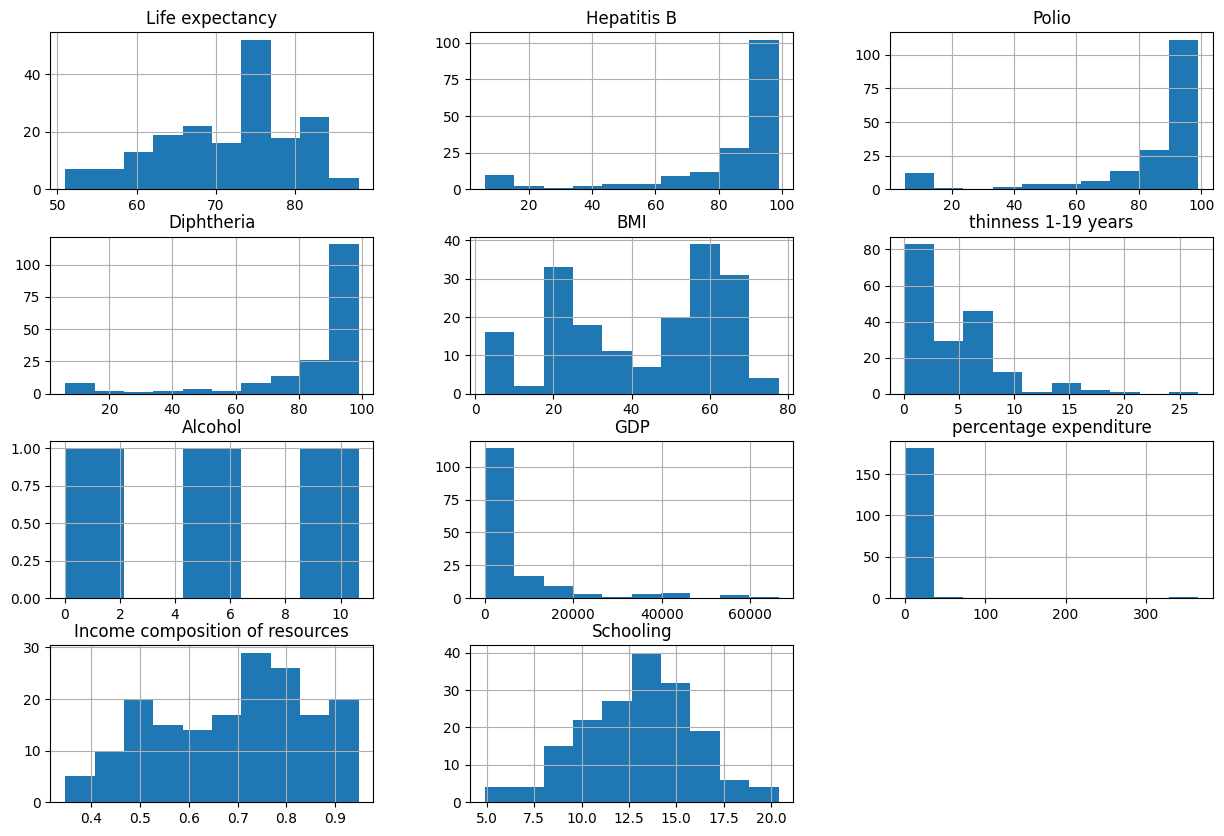

In [11]:
df3.hist(figsize= (15,10))

## 10. Plot a scatter matrix of all features and the target. Pay special attention to the bivariate relationship between every feature and the target. Describe any relationships as positive or negative.

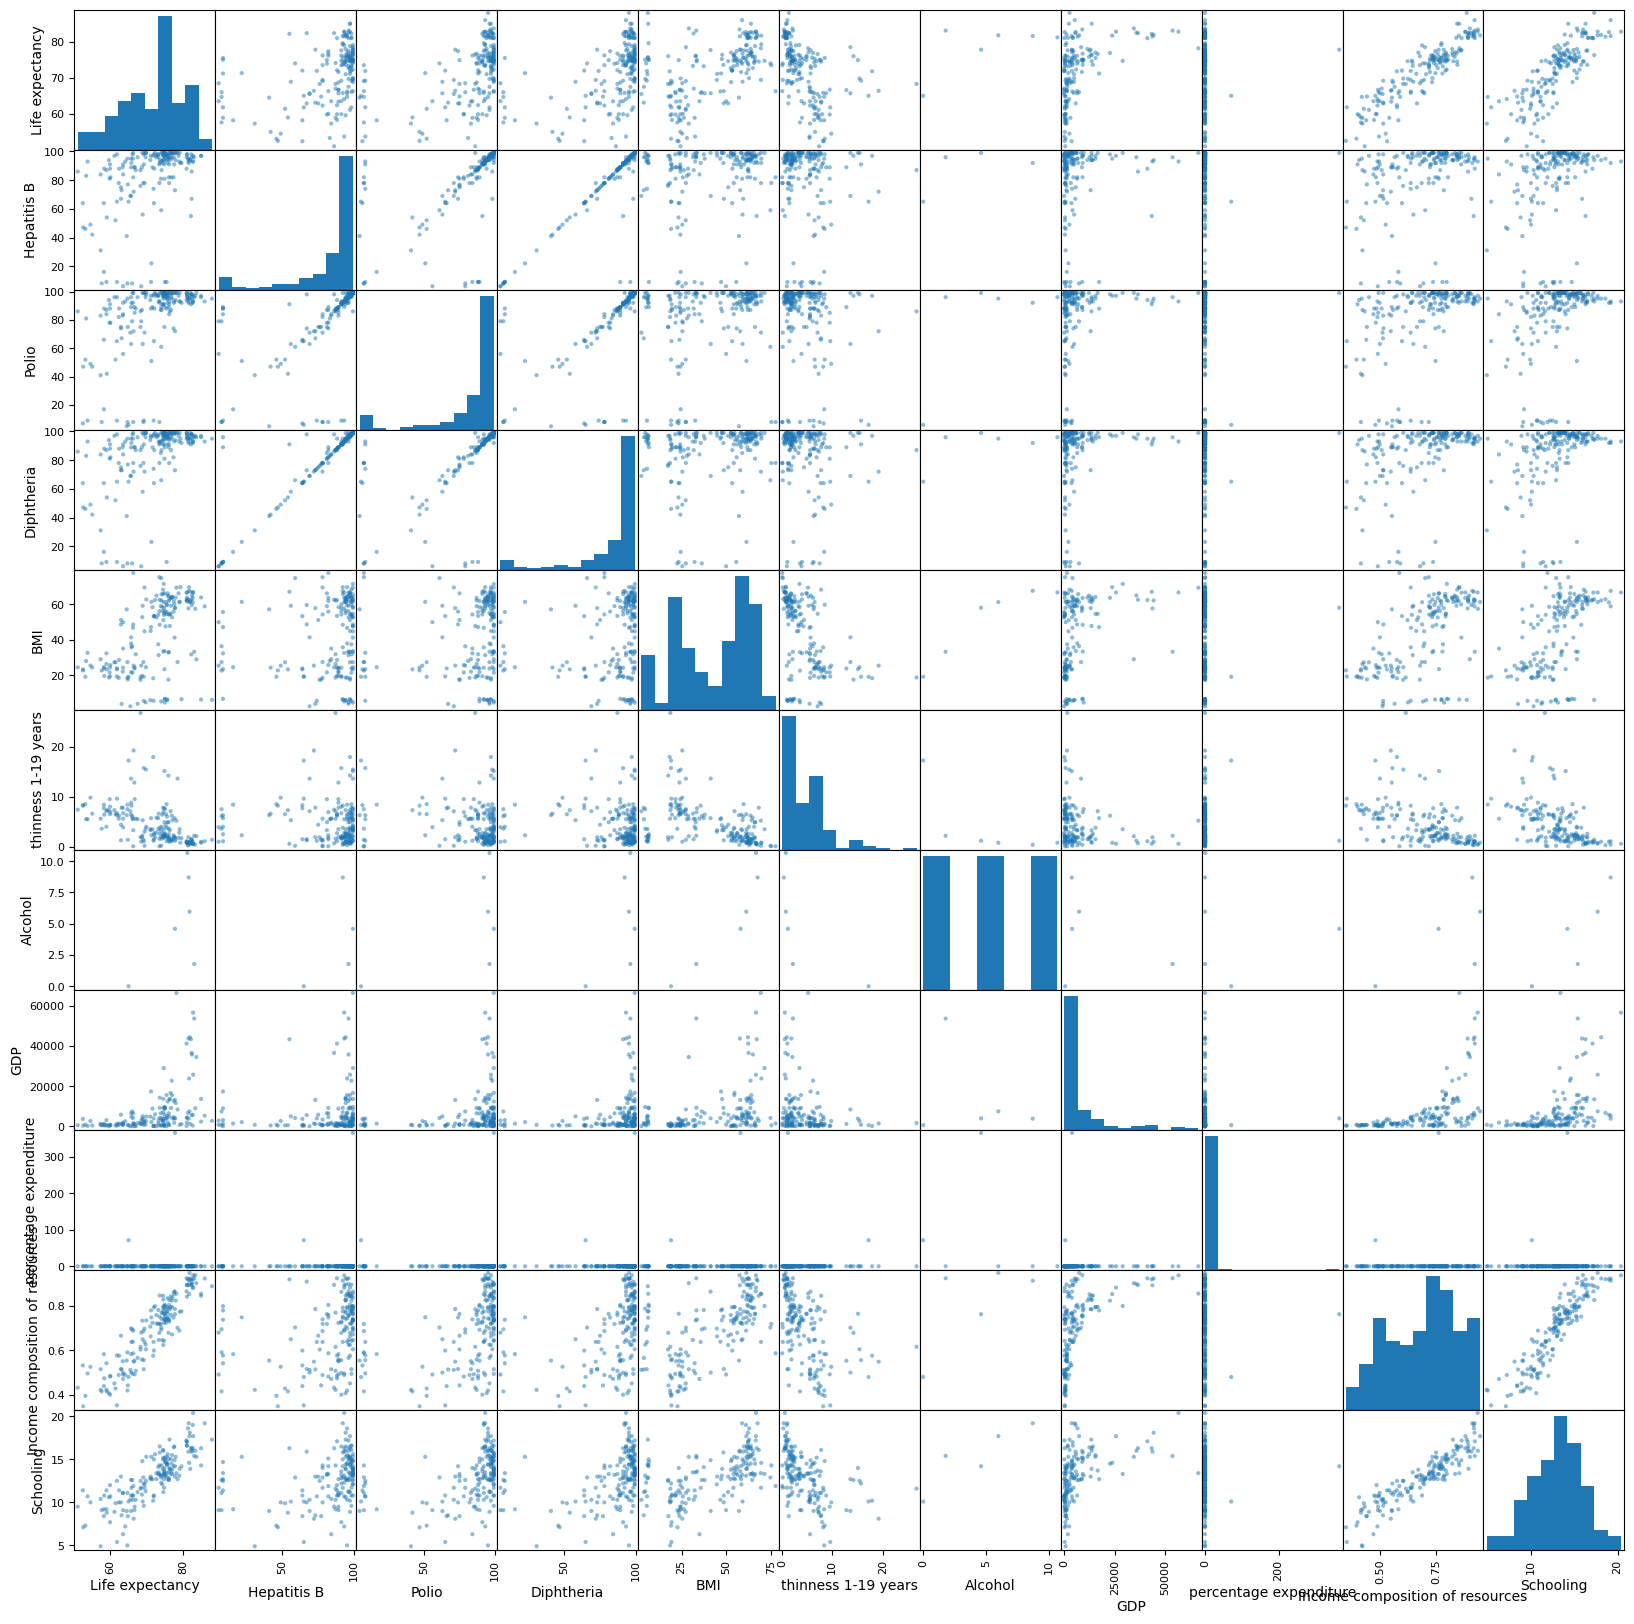

In [12]:
num_features = [
    "Hepatitis B",
    "Polio",
    "Diphtheria",
    "BMI",
    "thinness 1-19 years",
    "Alcohol",
    "GDP",
    "percentage expenditure",
    "Income composition of resources",
    "Schooling"
]

attributes = ["Life expectancy"] + num_features

scatter_matrix(
    df3[attributes],
    figsize=(20, 20),
    alpha=0.5
)

plt.show()

In [13]:
corr_matrix = df3[attributes].corr()

print(
    corr_matrix["Life expectancy"]
    .sort_values(ascending=False)
)

Life expectancy                    1.000000
Income composition of resources    0.907364
Schooling                          0.818159
Alcohol                            0.603775
BMI                                0.516663
Polio                              0.515602
Diphtheria                         0.500300
GDP                                0.454491
Hepatitis B                        0.420848
percentage expenditure             0.043964
thinness 1-19 years               -0.475020
Name: Life expectancy, dtype: float64


These features show positive correlations with life expectancy: income composition of resources, schooling, BMI, GDP, Polio vaccination, Diphtheria vaccination, and Hepatitis B vaccination. Thinness 1-19 years negatively correlates with life expectancy.

## 11. Plot GDP per capita on the x-axis and life expectancy on the y-axis. Add a linear regression line and describe their relationship.

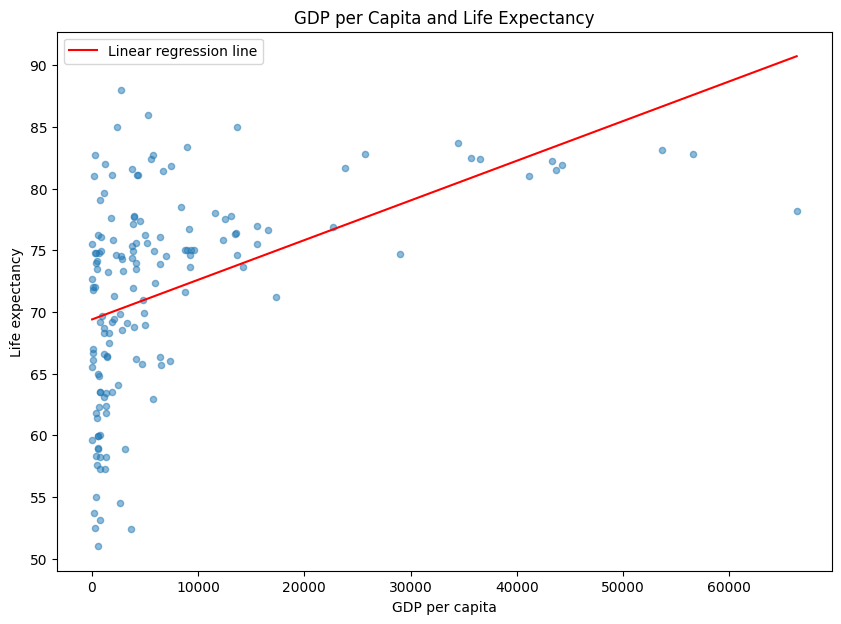

In [14]:
gdp_life = df3[["GDP", "Life expectancy"]].dropna()

gdp_life.plot(
    kind="scatter",
    x="GDP",
    y="Life expectancy",
    alpha=0.5,
    figsize=(10, 7)
)

beta1, beta0 = np.polyfit(
    gdp_life["GDP"],
    gdp_life["Life expectancy"],
    1
)

x_line = np.linspace(
    gdp_life["GDP"].min(),
    gdp_life["GDP"].max(),
    100
)

plt.plot(
    x_line,
    beta1 * x_line + beta0,
    "r",
    label="Linear regression line"
)

plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy")
plt.title("GDP per Capita and Life Expectancy")
plt.legend()
plt.show()

GDP per capita and life expectancy have a positive relationship. Countries with higher GDP per capita generally have higher life expectancy. However, the points are widely dispersed, and the relationship does not appear perfectly linear. There also seems to be a clustering around low GDP per capita countries that still have varying life expectancy.

## 12. Create a pipeline to process numerical features using `.Pipeline()`. The pipeline must first replace missing feature values with the median, then standardize the features.

In [15]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

## 13. Create a full pipeline to process numerical and categorical features using `.ColumnTransformer()`. One-hot encode the categorical feature, `Status`, using `.OneHotEncoder()`.

In [16]:
cat_features = ["Status"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

## 14. Separate the target and features into two separate NumPy arrays. Then split the dataframe into train and test sets, placing 20% of the data in the test set.

In [17]:
# Separate the target from the features
y = np.c_[df3["Life expectancy"]]
X = df3.drop("Life expectancy", axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Place 20% of observations in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Feature shape: (183, 11)
Target shape: (183, 1)
Training features: (146, 11)
Test features: (37, 11)
Training target: (146, 1)
Test target: (37, 1)


## 15. Fit and transform the train set using the full pipeline.

In [18]:
X_train_prepared = full_pipeline.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_prepared.shape)

Original training shape: (146, 11)
Processed training shape: (146, 12)


## 16. Transform the test set using the full pipeline.

In [19]:
X_test_prepared = full_pipeline.transform(X_test)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_prepared.shape)

Original test shape: (37, 11)
Processed test shape: (37, 12)


## 17. Train the train set using linear regression.

In [20]:
lin_reg = LinearRegression()

lin_reg.fit(X_train_prepared, y_train)

LinearRegression()

## 18. Print the first five predictions from the trained linear regression.

In [21]:
first_five_predictions = lin_reg.predict(X_train_prepared[:5])

print("Predictions:")
print(first_five_predictions)

print("\nActual life expectancy:")
print(y_train[:5])

Predictions:
[[74.28072207]
 [57.17686343]
 [80.13993878]
 [66.85026755]
 [76.3782001 ]]

Actual life expectancy:
[[73.6]
 [59. ]
 [82.2]
 [71.8]
 [79.1]]


## 19. Calculate the root mean square error (RMSE) using the test set.

In [23]:
# Predict life expectancy for the test set
y_pred_lin = lin_reg.predict(X_test_prepared)

# Calculate mean squared error, then take its square root
lin_mse = mean_squared_error(y_test, y_pred_lin)
lin_rmse = np.sqrt(lin_mse)

print("Linear regression test RMSE:", lin_rmse)

Linear regression test RMSE: 4.949615157038575


## 20. Conduct 5-fold cross-validation with a random-forest regression and calculate the mean RMSE on the train set.

In [25]:
forest_reg = RandomForestRegressor(random_state=1)

scores = cross_val_score(
    forest_reg,
    X_train_prepared,
    y_train.ravel(),
    scoring="neg_mean_squared_error",
    cv=5
)

forest_rmse_scores = np.sqrt(-scores)

print("RMSE for each fold:", forest_rmse_scores)
print("Mean RMSE:", forest_rmse_scores.mean())

RMSE for each fold: [2.33906961 6.20047818 3.46445616 3.26706872 3.88367328]
Mean RMSE: 3.830949189036833


## 21. Conduct a grid search for random-forest regression. Search values for the hyperparameters `n_estimators` and `max_features`.

In [26]:
param_grid = [{
    "n_estimators": np.arange(10, 100, 10),
    "max_features": np.arange(
        1,
        X_train_prepared.shape[1] + 1
    )
}]

grid_search = GridSearchCV(
    forest_reg,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

grid_search.fit(
    X_train_prepared,
    y_train.ravel()
)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=1), n_jobs=-1,
             param_grid=[{'max_features': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12]),
                          'n_estimators': array([10, 20, 30, 40, 50, 60, 70, 80, 90])}],
             return_train_score=True, scoring='neg_mean_squared_error')

## 22. Report the best parameter values.

In [27]:
grid_search.best_params_

{'max_features': np.int64(1), 'n_estimators': np.int64(80)}

## 23. Use the best model as the final model and evaluate it on the test set. What is the RMSE?

In [32]:
# evaluate the model on the test set
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test_prepared)
final_mse = mean_squared_error(y_pred_final, y_test)
final_rmse = np.sqrt(final_mse)
print(final_rmse)

4.078594423899266


## 24. Fit the final model on the entire dataset (combined train and test sets). Print feature importance beside the corresponding feature name, sorted in descending order. Which three features have the highest importance?

In [34]:
# Refit preprocessing using the complete dataset
X_all_prepared = full_pipeline.fit_transform(X)

# Refit the selected model using all observations
final_model.fit(
    X_all_prepared,
    y.ravel()
)


RandomForestRegressor(max_features=np.int64(1), n_estimators=np.int64(80),
                      random_state=1)

In [33]:
# Get the names created by one-hot encoding
cat_encoder = full_pipeline.named_transformers_["cat"]

cat_one_hot_features = list(
    cat_encoder.get_feature_names_out(cat_features)
)

# Numerical names followed by encoded categorical names
feature_names = num_features + cat_one_hot_features

# Match each feature with its importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_model.feature_importances_
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

                        Feature  Importance
                      Schooling    0.175296
            thinness 1-19 years    0.163215
Income composition of resources    0.131563
                          Polio    0.110914
                    Hepatitis B    0.096859
                            BMI    0.086405
                            GDP    0.085885
                     Diphtheria    0.083982
              Status_Developing    0.034836
               Status_Developed    0.025465
                        Alcohol    0.004200
         percentage expenditure    0.001380
